# Dataset

Use the Pima Indians Diabetes Dataset.

Dataset link:
https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database

The dataset contains medical information such as:

Pregnancies

Glucose

Blood Pressure

Skin Thickness

Insulin

BMI

Diabetes Pedigree Function

Age

The target variable is:

Outcome

0 → No diabetes

1 → Diabetes

Important Import

In [3]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split

Load the Dataset

In [4]:
df = pd.read_csv("diabetes.csv")

In [5]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Display the dataset structure using .info() and .describe()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
# Insulin --> outliers 
# Pregnancies --> outliers
# BloodPressure --> outliers

Visualize the distribution of the target variable.

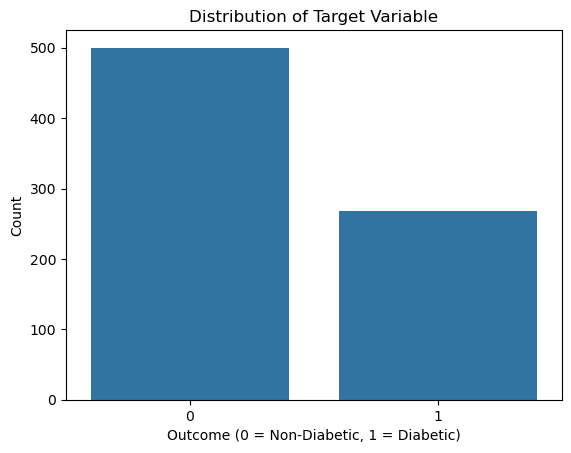

In [9]:
sns.countplot(x='Outcome', data=df)
plt.title('Distribution of Target Variable')
plt.xlabel('Outcome (0 = Non-Diabetic, 1 = Diabetic)')
plt.ylabel('Count')
plt.show()

Create a correlation heatmap.

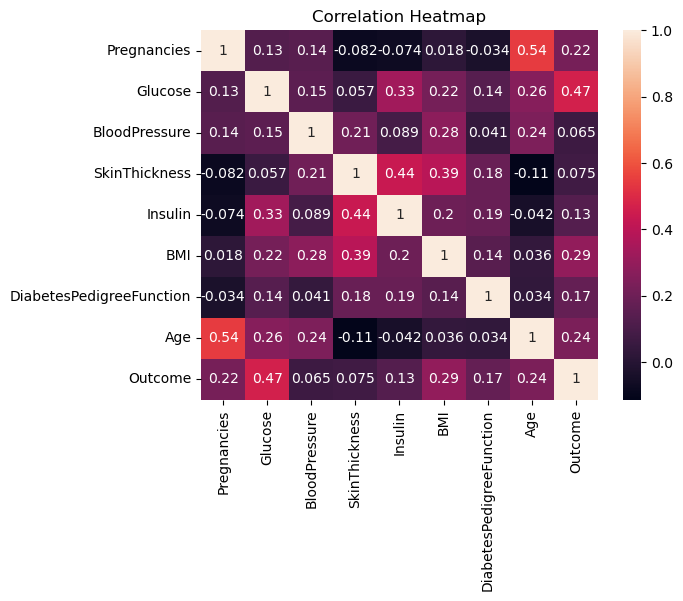

In [10]:
sns.heatmap(df.corr(), annot=True)
plt.title('Correlation Heatmap')
plt.show()

In [11]:
# Which features seem most related to diabetes?

Identify invalid or missing values.

In [12]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Identify features that contain invalid values.

In [13]:
cols = ['Pregnancies','Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print((df[cols] == 0).sum())

Pregnancies      111
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


Replace them using median imputation.

In [14]:
df[cols] = df[cols].replace(0,np.nan)

In [15]:
df.isnull().sum()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [16]:
# will you replace the zero values with median directly? if yes is it a good idea? if no, how will you do it?
# No, I will not replace the zeros directly with the median.
# First, I convert the zeros to NaN because zero is an invalid value
# for these features, and keeping them would pull the median down.
# Then I compute the median from the valid values only and fill the NaNs.
# This is a good idea in general because the median is robust to outliers
# and suits skewed medical data. However, for Insulin and SkinThickness,
# many values are missing (~49% and ~30%), so median imputation reduces
# variance and weakens the relationship with the target.


df['Glucose'].fillna(df.Glucose.median(),inplace = True)
df['Pregnancies'].fillna(df.Pregnancies.median(),inplace = True)
df['BloodPressure'].fillna(df.BloodPressure.median(),inplace = True)
df['BMI'].fillna(df.BMI.median(),inplace = True)
df['SkinThickness'].fillna(df.SkinThickness.median(),inplace = True)
df['Insulin'].fillna(df.Insulin.median(),inplace = True)




In [17]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [18]:
#Justify why median is a good choice.
# 1. Robust to outliers: extreme values (e.g., very high Insulin or
#    Glucose readings) do not affect the median, while they pull the
#    mean up and distort the imputed value.
# 2. Suits skewed data: medical features such as Insulin are right-skewed,
#    so the median represents a typical patient better than the mean.
# 3. Preserves the distribution reasonably: the imputed value comes from the
#    middle of the real data, so it does not shift the distribution as much
#    as the mean would.
# 4. Simple and fast: no model is needed, and it is better than deleting
#    rows, which would lose a large part of the dataset (e.g., ~49% in Insulin).
# Limitation: with many missing values (Insulin, SkinThickness), many rows
# get the same value, which reduces variance. KNN imputation could be a
# better alternative.

Split Data To target and features

In [19]:
x = df.drop(columns = 'Outcome')
y = df.Outcome

split Data to training and testing data

In [20]:
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2, random_state=42 , stratify=y)

In [21]:
print(f'x_train shape -->{x_train.shape}')
print(f'y_train shape -->{y_train.shape}')
print('--'*10)
print(f'x_test shape -->{x_test.shape}')
print(f'y_test shape -->{y_test.shape}')

x_train shape -->(614, 8)
y_train shape -->(614,)
--------------------
x_test shape -->(154, 8)
y_test shape -->(154,)


Transform the Data (using Standerd scaler)

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train[['Pregnancies','Glucose','BloodPressure','SkinThickness', 'Insulin','BMI','Age','DiabetesPedigreeFunction']] = scaler.fit_transform(x_train[['Pregnancies','Glucose','BloodPressure','SkinThickness', 'Insulin','BMI','Age','DiabetesPedigreeFunction']])
x_test[['Pregnancies','Glucose','BloodPressure','SkinThickness', 'Insulin','BMI','Age','DiabetesPedigreeFunction']] = scaler.transform(x_test[['Pregnancies','Glucose','BloodPressure','SkinThickness', 'Insulin','BMI','Age','DiabetesPedigreeFunction']])

In [23]:
x_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,-1.147221,-1.056427,-0.826740,-1.918187,-1.203361,-0.769477,0.310794,-0.792169
711,0.213269,0.144399,0.477772,-0.229874,-1.470195,-0.417498,-0.116439,0.561034
373,-0.807099,-0.556083,-1.152868,1.233330,-0.555335,0.359790,-0.764862,-0.707594
46,-1.147221,0.811525,-1.315932,-0.004766,-0.161437,-0.402832,0.262314,-0.369293
682,-0.126854,-0.889646,-0.663676,1.120776,-0.415565,1.782373,-0.337630,-0.961320


In [24]:
x_test.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
44,0.893514,1.245157,-0.663676,-0.004766,-0.161437,-0.740145,-0.555791,0.561034
672,1.913882,-1.790266,2.760669,-0.680091,-1.127122,0.447785,-0.583061,1.153060
700,-0.807099,0.010974,0.314708,-0.229874,0.791541,0.506448,0.016882,-0.623019
630,0.893514,-0.255876,-0.663676,-0.004766,-0.161437,-0.740145,0.771356,0.053583
81,-0.807099,-1.590128,-0.011420,-0.004766,-0.161437,-0.021521,-1.137554,-0.961320


In [25]:
# does it matter if we scale the data or not?
# yes matter 

Train an SVM model using:

•	Linear Kernel

•	RBF Kernel

•	Polynomial Kernel


In [26]:
from sklearn.svm import SVC
svc_linear = SVC(kernel='linear',C=0.1)
svc_linear.fit(x_train,y_train)


,C,0.1
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [27]:
svc_rbf = SVC(kernel='rbf', C=1, gamma='scale', random_state=42)
svc_rbf.fit(x_train, y_train)


,C,1
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [28]:
svc_poly = SVC(kernel='poly',C=0.1)
svc_poly.fit(x_train,y_train)


,C,0.1
,kernel,'poly'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


Evaluate each model using:

•	Accuracy

•	Classification Report


In [29]:
from sklearn.metrics import accuracy_score, classification_report

In [30]:
y_pred_linear = svc_linear.predict(x_test)
acc_linear = accuracy_score(y_test, y_pred_linear)
print("Linear Accuracy:", acc_linear)
print(classification_report(y_test, y_pred_linear))

Linear Accuracy: 0.7207792207792207
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       100
           1       0.63      0.50      0.56        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.68       154
weighted avg       0.71      0.72      0.71       154



In [31]:
y_pred_rbf = svc_rbf.predict(x_test)
print("RBF Accuracy:",accuracy_score(y_test, y_pred_rbf))
print(classification_report(y_test, y_pred_rbf))

RBF Accuracy: 0.7532467532467533
              precision    recall  f1-score   support

           0       0.78      0.86      0.82       100
           1       0.68      0.56      0.61        54

    accuracy                           0.75       154
   macro avg       0.73      0.71      0.72       154
weighted avg       0.75      0.75      0.75       154



In [32]:
y_pred_poly = svc_poly.predict(x_test)
acc_poly = accuracy_score(y_test, y_pred_poly)
print("poly Accuracy:", acc_poly)
print(classification_report(y_test, y_pred_poly))

poly Accuracy: 0.7012987012987013
              precision    recall  f1-score   support

           0       0.70      0.94      0.80       100
           1       0.70      0.26      0.38        54

    accuracy                           0.70       154
   macro avg       0.70      0.60      0.59       154
weighted avg       0.70      0.70      0.65       154



In [33]:
# Compare the results.
# - RBF kernel gave the best results: highest accuracy (0.753) and the best
#   balance for the diabetic class (recall = 0.56, f1 = 0.61). This suggests
#   the decision boundary between the classes is non-linear, and RBF can
#   capture it.
# - Linear kernel came second (accuracy 0.721, recall = 0.50, f1 = 0.56),
#   which means the data is partly linearly separable.
# - Poly kernel gave 0.701 accuracy. It has the highest precision for
#   diabetic (0.70), but its recall is only 0.26, so it misses most
#   diabetic patients.
# - Accuracy alone can be misleading because the data is imbalanced (65/35).
#   In a medical setting, recall of the diabetic class matters most, because
#   missing a patient is worse than a false alarm.
# - Best model: RBF kernel.

Tune the SVM model using GridSearchCV.

Tune the following parameters:

•	C

•	gamma

•	kernel


In [34]:
from sklearn.model_selection import GridSearchCV

In [35]:
model = SVC() 

In [36]:
params = [
    {
        'kernel': ['linear'],
        'C': [0.01, 0.1, 1, 10]
    },


    {
        'kernel': ['rbf'],
        'C': [0.01, 0.1, 1, 10],
        'gamma': [0.01, 0.1, 1, 10]
    },

    {
        'kernel': ['poly'],
        'C': [0.1, 1],
        'gamma': [0.01, 0.1],
        'degree': [2, 3]
    }
]

In [37]:
grid_search = GridSearchCV(model,params,cv=5,scoring='accuracy')

In [38]:
grid_search.fit(x_train,y_train)

,estimator,SVC()
,param_grid,"[{'C': [0.01, 0.1, ...], 'kernel': ['linear']}, {'C': [0.01, 0.1, ...], 'gamma': [0.01, 0.1, ...], 'kernel': ['rbf']}, ...]"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,10


In [39]:
# Report the best parameter combination.
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)


Best Parameters: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV Score: 0.7866186858589899


Evaluate the Best Model
 

In [40]:
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(x_test)
print("Best Model Accuracy:", accuracy_score(y_test, y_pred_best))
print(classification_report(y_test, y_pred_best))

Best Model Accuracy: 0.6948051948051948
              precision    recall  f1-score   support

           0       0.74      0.81      0.78       100
           1       0.58      0.48      0.53        54

    accuracy                           0.69       154
   macro avg       0.66      0.65      0.65       154
weighted avg       0.69      0.69      0.69       154



Print the number of support vectors.

In [42]:
best_model = grid_search.best_estimator_
print("Total support vectors:", len(best_model.support_vectors_))
print("Per class:", best_model.n_support_)

Total support vectors: 313
Per class: [156 157]


Print the number of support vectors.

In [43]:
ratio = len(best_model.support_vectors_) / len(x_train)
print("Ratio:", ratio)
print("Percentage:", ratio * 100, "%")

Ratio: 0.509771986970684
Percentage: 50.9771986970684 %


In [ ]:
#Explain why these points are important
# Ratio of support vectors to the dataset size:
# Number of support vectors = 313
# Training set size = 614
# Ratio = 313 / 614 = 0.51 (about 51%)
# Almost half of the training points are support vectors. This is a high
# ratio, which means the two classes overlap and there is no clear gap
# between them.

Simulate noisy medical data by adding noise to one feature (e.g., glucose).

In [44]:
# you can use Pandas to add noise to the dataset.
np.random.seed(42)
x_train_noisy = x_train.copy()
x_test_noisy = x_test.copy()
noise_level = 0.5  
x_train_noisy['Glucose'] += np.random.normal(0, noise_level, size=len(x_train_noisy))
x_test_noisy['Glucose'] += np.random.normal(0, noise_level, size=len(x_test_noisy))


In [45]:
print("Original Glucose std:", x_train['Glucose'].std())
print("Noisy Glucose std   :", x_train_noisy['Glucose'].std())

Original Glucose std: 1.0008153283050325
Noisy Glucose std   : 1.0903382894498286


Retrain the model and compare the performance.

In [47]:
svm_noisy = SVC(C=10, gamma=0.01, kernel='rbf', random_state=42)
svm_noisy.fit(x_train_noisy, y_train)
y_pred_noisy = svm_noisy.predict(x_test_noisy)
print("Noisy Accuracy:", accuracy_score(y_test, y_pred_noisy))
print(classification_report(y_test, y_pred_noisy))

Noisy Accuracy: 0.7402597402597403
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



In [ ]:
# Explain the results.
# Original model: accuracy = 0.695, recall (diabetic) = 0.48
# Noisy model:    accuracy = 0.740, recall (diabetic) = 0.56
#
# - Surprisingly, adding Gaussian noise (std = 0.5) to Glucose did not
#   reduce performance; accuracy and recall slightly increased.
# - This shows the SVM is robust to moderate noise in a single feature:
#   the other features (BMI, Age, ...) still carry information, and the
#   RBF kernel with a small gamma produces a smooth boundary.
# - The improvement is probably not a real gain. The test set has only 154
#   samples, so a 4.5% difference is about 7 patients and may be due to
#   chance. The noise may also act like regularization, reducing the
#   overfitting of the model with C = 10.
# - We would expect performance to drop with a much higher noise level,
#   since Glucose is the feature most correlated with the target.
# - Conclusion: the model is reasonably robust to moderate noise.

Compare SVM with other machine learning models `(Bonus)`

•	Logistic Regression

•	Random Forest

